# Notebook 03 - Baseline Observational Marketing Mix Model

## Northstar Hydration

In Notebook 02 we learned that media, price, promotions, distribution, competition, seasonality, and demand conditions all move together.

Now we build our first **observational Marketing Mix Model (MMM)**.

The purpose of this notebook is to estimate:

- media carryover (adstock);
- diminishing returns (saturation);
- channel contribution;
- uncertainty around those estimates;
- how well the model explains observed weekly sales.

## Important limitation

This is **not yet an incrementality-calibrated model**.

The model learns from historical observational data. If media spend is correlated with unobserved demand, the MMM can still attribute too much sales lift to media.

That limitation is intentional. Notebook 04 will create a geo incrementality experiment and ask:

> **Does the causal experiment agree with what the MMM thinks?**

## Why use a national weekly baseline first?

Our source dataset contains **20 markets × 104 weeks = 2,080 observations**.

For the first MMM, we aggregate those markets into one national weekly series with **104 weekly observations**. This makes the first Bayesian model easier to understand while we refresh Python and MMM concepts.

Later notebooks return to market-level data for geo incrementality tests, heterogeneous pricing response, and richer market-level modeling.

## 1. Install PyMC-Marketing

Run this once at the start of a fresh Google Colab session.

In [ ]:
%pip install -q -U pymc-marketing arviz

If Colab asks you to restart the runtime after installing packages, restart the session and rerun the notebook from the top.

## 2. Imports and project setup

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az

import pymc as pm
import pymc_marketing

from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation, MMM

SEED = 42
rng = np.random.default_rng(SEED)

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/northstar_cpg")
    except ImportError:
        PROJECT_DIR = Path("/mnt/data/northstar_cpg")
else:
    PROJECT_DIR = Path("/mnt/data/northstar_cpg")

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "northstar_modeling_data.csv"

if not DATA_PATH.exists():
    local_fallback = Path("/mnt/data/northstar_cpg/northstar_modeling_data.csv")
    if local_fallback.exists():
        DATA_PATH = local_fallback

print("PyMC-Marketing version:", pymc_marketing.__version__)
print("PyMC version:", pm.__version__)
print("Data:", DATA_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyMC-Marketing version: 1.2.0
PyMC version: 6.3.2
Data: /content/drive/MyDrive/northstar_cpg/data/northstar_modeling_data.csv


## 3. Load the market-level data

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "northstar_modeling_data.csv was not found. Run Notebook 01 first."
    )

df = pd.read_csv(DATA_PATH, parse_dates=["week"])

print("Market-level shape:", df.shape)
print("Markets:", df["market"].nunique())
print("Weeks:", df["week"].nunique())

df.head()

Market-level shape: (2080, 24)
Markets: 20
Weeks: 104


,week,market,week_number,year,month,units,retail_sales,manufacturer_net_revenue,gross_profit_before_media,contribution_profit_after_media,...,competitor_price,relative_price_index,distribution,ctv_spend,social_spend,retail_media_spend,search_spend,total_media_spend,summer_event,seasonality_index
0,2024-01-01,Atlanta,0,2024,1,23663,241399.493440,168979.645408,88525.445408,78774.424119,...,9.634526,1.058854,0.692153,0.000000,3903.727442,4221.852802,1625.441045,9751.021289,0,0.832274
1,2024-01-01,Boston,0,2024,1,21680,215461.829159,150823.280411,77111.280411,55655.807923,...,9.223515,1.077493,0.793102,10004.174275,6238.589426,833.127225,4379.581561,21455.472488,0,0.832274
2,2024-01-01,Charlotte,0,2024,1,28290,283772.853647,198640.997553,102454.997553,86375.002478,...,9.679983,1.036247,0.728758,6196.089517,1692.947724,5641.816389,2549.141445,16079.995075,0,0.832274
3,2024-01-01,Chicago,0,2024,1,21840,221603.320671,155122.324469,80866.324469,72521.010366,...,9.696447,1.046432,0.664752,0.000000,4461.380167,2103.378947,1780.554989,8345.314103,0,0.832274
4,2024-01-01,Dallas,0,2024,1,15813,156938.482760,109856.937932,56092.737932,35856.439884,...,9.349673,1.061497,0.760444,14682.126378,2191.366859,1190.037680,2172.767131,20236.298048,0,0.832274


## 4. Aggregate to a national weekly series

For **sales and media spend**, we use totals across markets.

For **price, competitor price, and distribution**, we use weekly averages across markets.

`promo_share` is the fraction of markets on promotion in a given week. For example, `0.25` means about 25% of markets are on promotion.

In [ ]:
weekly = (
    df.groupby("week", as_index=False)
      .agg(
          total_units=("units", "sum"),
          ctv_spend=("ctv_spend", "sum"),
          social_spend=("social_spend", "sum"),
          retail_media_spend=("retail_media_spend", "sum"),
          search_spend=("search_spend", "sum"),
          avg_actual_price=("actual_price", "mean"),
          promo_share=("promo_flag", "mean"),
          avg_competitor_price=("competitor_price", "mean"),
          avg_distribution=("distribution", "mean"),
          summer_event=("summer_event", "max"),
      )
      .sort_values("week")
      .reset_index(drop=True)
)

print("National weekly shape:", weekly.shape)
weekly.head()

National weekly shape: (104, 11)


,week,total_units,ctv_spend,social_spend,retail_media_spend,search_spend,avg_actual_price,promo_share,avg_competitor_price,avg_distribution,summer_event
0,2024-01-01,405782,121338.501964,91936.503240,75266.698873,40168.989218,10.009182,0.00,9.377048,0.703935,0
1,2024-01-08,443829,81283.291783,86026.978337,105520.813682,39523.516318,9.757568,0.25,9.362256,0.697421,0
2,2024-01-15,471644,113436.253231,83483.179404,92852.178353,44810.499465,9.659576,0.30,9.397724,0.704805,0
3,2024-01-22,435812,55484.413349,91422.252651,91237.304942,40084.386480,9.857525,0.15,9.406296,0.701105,0
4,2024-01-29,442169,23745.576237,113199.963124,83309.115041,39604.820415,9.760368,0.15,9.423900,0.699265,0


We deliberately do **not** add `relative_price_index` as another control here because it is constructed from Northstar price and competitor price. Including all three would add redundant information.

## 5. Inspect the national weekly series

In [ ]:
weekly.describe().T

,count,mean,min,25%,50%,75%,max,std
week,104,2024-12-26 12:00:00,2024-01-01 00:00:00,2024-06-29 06:00:00,2024-12-26 12:00:00,2025-06-24 18:00:00,2025-12-22 00:00:00,NaN
total_units,104.0,574892.923077,405782.0,514820.5,568292.0,633905.25,742001.0,71524.369819
ctv_spend,104.0,120347.905025,23745.576237,90357.9053,121263.481693,144199.124453,224909.29523,41254.46011
social_spend,104.0,104505.511781,76021.907874,95177.348035,104003.190509,113211.928421,153185.635408,14241.272803
retail_media_spend,104.0,83208.231133,60701.520387,73668.411674,83249.44885,90580.91525,116494.453946,12653.891742
search_spend,104.0,40924.910993,29887.144489,36768.696549,40746.878128,43880.399264,54339.179632,5220.188804
avg_actual_price,104.0,9.952832,9.405998,9.760501,9.925351,10.151459,10.359182,0.225931
promo_share,104.0,0.166346,0.0,0.1,0.15,0.2125,0.5,0.097901
avg_competitor_price,104.0,9.486755,9.359738,9.441604,9.486269,9.541322,9.600721,0.063455
avg_distribution,104.0,0.7484,0.697421,0.724595,0.748823,0.773299,0.801471,0.029695


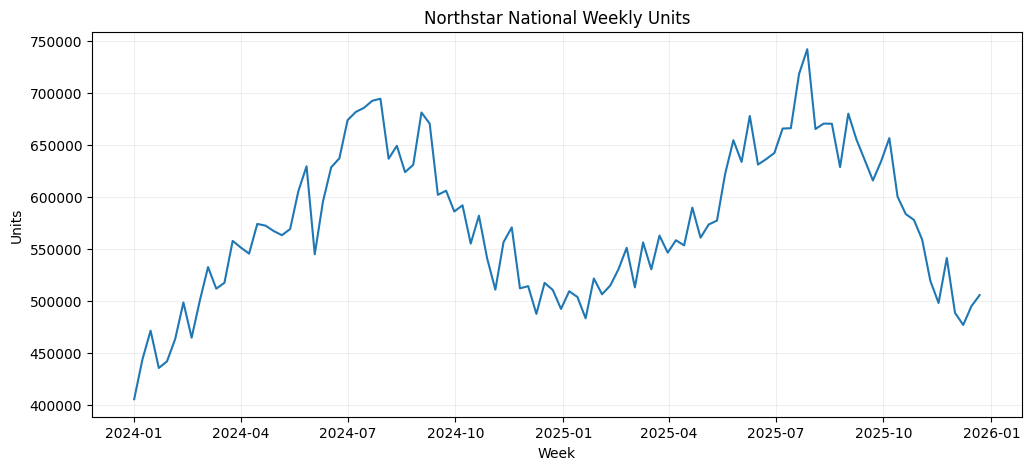

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(weekly["week"], weekly["total_units"])
plt.title("Northstar National Weekly Units")
plt.xlabel("Week")
plt.ylabel("Units")
plt.grid(alpha=0.2)
plt.show()

## 6. Inspect correlations before modeling

In [ ]:
check_cols = [
    "total_units",
    "ctv_spend",
    "social_spend",
    "retail_media_spend",
    "search_spend",
    "avg_actual_price",
    "promo_share",
    "avg_competitor_price",
    "avg_distribution",
    "summer_event",
]

weekly[check_cols].corr().round(2)

,total_units,ctv_spend,social_spend,retail_media_spend,search_spend,avg_actual_price,promo_share,avg_competitor_price,avg_distribution,summer_event
total_units,1.00,0.61,0.24,-0.29,0.23,0.33,-0.27,0.29,0.28,0.60
ctv_spend,0.61,1.00,0.27,-0.22,0.22,0.11,-0.21,-0.00,-0.01,0.37
social_spend,0.24,0.27,1.00,-0.18,0.03,-0.02,-0.21,-0.14,-0.14,0.22
retail_media_spend,-0.29,-0.22,-0.18,1.00,-0.15,-0.22,0.52,0.07,0.07,-0.11
search_spend,0.23,0.22,0.03,-0.15,1.00,0.22,-0.25,0.01,0.04,0.08
avg_actual_price,0.33,0.11,-0.02,-0.22,0.22,1.00,-0.66,0.64,0.67,0.05
promo_share,-0.27,-0.21,-0.21,0.52,-0.25,-0.66,1.00,-0.04,-0.05,-0.10
avg_competitor_price,0.29,-0.00,-0.14,0.07,0.01,0.64,-0.04,1.00,0.95,0.02
avg_distribution,0.28,-0.01,-0.14,0.07,0.04,0.67,-0.05,0.95,1.00,0.02
summer_event,0.60,0.37,0.22,-0.11,0.08,0.05,-0.10,0.02,0.02,1.00


Do not read this correlation matrix as causal evidence. Media can rise when expected demand is high, retail media can move with promotions, and distribution can trend over time. The MMM tries to separate these signals, but observational data can still contain residual confounding.

## 7. Define channels, controls, X, and y

In [ ]:
CHANNEL_COLUMNS = [
    "ctv_spend",
    "social_spend",
    "retail_media_spend",
    "search_spend",
]

controls_to_standardize = [
    "avg_actual_price",
    "promo_share",
    "avg_competitor_price",
    "avg_distribution",
]

for col in controls_to_standardize:
    weekly[f"{col}_z"] = (
        weekly[col] - weekly[col].mean()
    ) / weekly[col].std()


CONTROL_COLUMNS = [
    "avg_actual_price_z",
    "promo_share_z",
    "avg_competitor_price_z",
    "avg_distribution_z",
    "summer_event",
]

FEATURE_COLUMNS = ["week", *CHANNEL_COLUMNS, *CONTROL_COLUMNS]

X = weekly[FEATURE_COLUMNS].copy()
y = weekly["total_units"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (104, 10)
y shape: (104,)


,week,ctv_spend,social_spend,retail_media_spend,search_spend,avg_actual_price_z,promo_share_z,avg_competitor_price_z,avg_distribution_z,summer_event
0,2024-01-01,121338.501964,91936.503240,75266.698873,40168.989218,0.249412,-1.699129,-1.728879,-1.497379,0
1,2024-01-08,81283.291783,86026.978337,105520.813682,39523.516318,-0.864262,0.854475,-1.961998,-1.716717,0
2,2024-01-15,113436.253231,83483.179404,92852.178353,44810.499465,-1.297988,1.365196,-1.403050,-1.468087,0
3,2024-01-22,55484.413349,91422.252651,91237.304942,40084.386480,-0.421838,-0.166966,-1.267967,-1.592672,0
4,2024-01-29,23745.576237,113199.963124,83309.115041,39604.820415,-0.851868,-0.166966,-0.990537,-1.654639,0


### What are `X` and `y`?

`X` contains the explanatory inputs/features. `y` contains the outcome we want to explain: total weekly units.

## 8. Define the baseline MMM

We use three core MMM ideas:

### Geometric adstock
Advertising can carry over into later weeks. `l_max=8` allows up to eight weeks of media history.

### Logistic saturation
Advertising has diminishing returns, so another dollar does not remain equally productive forever.

### Yearly seasonality
`yearly_seasonality=2` gives the model Fourier terms that can learn repeating annual patterns instead of forcing media to explain them.

In [ ]:
total_spend_per_channel = weekly[CHANNEL_COLUMNS].sum(axis=0)
spend_share = (
    total_spend_per_channel
    / total_spend_per_channel.sum()
)

media_prior_sigma = (
    0.75 * spend_share
).to_numpy()

media_prior_sigma

array([0.25863726, 0.2245907 , 0.17882114, 0.0879509 ])

In [ ]:
from pymc_extras.prior import Prior

model_config = {
    "intercept": Prior(
        "Normal",
        mu=0.60,
        sigma=0.10
    ),

    "gamma_control": Prior(
        "Normal",
        mu=0,
        sigma=0.10,
        dims="control"
    ),

    "gamma_fourier": Prior(
        "Laplace",
        mu=0,
        b=0.20,
        dims="fourier_mode"
    ),

    "saturation_beta": Prior(
        "HalfNormal",
        sigma=media_prior_sigma,
        dims="channel"
    ),

    "likelihood": Prior(
        "Normal",
        sigma=Prior(
            "HalfNormal",
            sigma=0.10
        ),
        dims="date"
    ),
}

In [ ]:
mmm = MMM(
    date_column="week",
    target_column="total_units",
    channel_columns=CHANNEL_COLUMNS,
    control_columns=CONTROL_COLUMNS,
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,
    model_config=model_config,
)

mmm.plot_suite = "new"

In [ ]:
mmm.model_config["saturation_beta"]

Prior("HalfNormal", sigma=[0.25863726 0.2245907  0.17882114 0.0879509 ], dims="channel")

## 9. Build the model and retain contributions in the original unit-sales scale

In [ ]:
mmm.build_model(X, y)

mmm.add_original_scale_contribution_variable(
    var=[
        "channel_contribution",
        "control_contribution",
        "intercept_contribution",
        "yearly_seasonality_contribution",
        "y",
    ]
)

mmm.table()

/usr/local/lib/python3.13/dist-packages/pymc_extras/prior.py:875: UserWarning: Implicit conversion of array-like parameter sigma to DataArray with dims ('channel',). Use DataArray with explicit dims to avoid this warning
  return _param_value_with_dims(param, value, dims=self.dims)


                                 Variable  Expression                                  Dimensions                  
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                          channel_scale =  Data                                        channel[4]                  
                           target_scale =  Data                                                                    
                           channel_data =  Data                                        date[104] × channel[4]      
                            target_data =  Data                                        date[104]                   
                           control_data =  Data                                        date[104] × control[5]      
                              dayofyear =  Data                                        date[104]                   
                                                                                                                   
                 intercept_contribution ~  Normal(0.6, 0.1)                                                        
                          adstock_alpha ~  Beta(1, 3)                                  channel[4]                  
                         saturation_lam ~  Gamma(3, <constant>)                        channel[4]                  
                        saturation_beta ~  HalfNormal(0, <constant>)                   channel[4]                  
                          gamma_control ~  Normal(0, 0.1)                              control[5]                  
                          gamma_fourier ~  Laplace(0, 0.2)                             fourier_mode[4]             
                                y_sigma ~  HalfNormal(0, 0.1)                                                      
                                                                                       Parameter count = 23        
                                                                                                                   
                   channel_contribution =  f(saturation_beta, saturation_lam,          date[104] × channel[4]      
                                           adstock_alpha)                                                          
                   control_contribution =  f(gamma_control)                            date[104] × control[5]      
                   fourier_contribution =  f(gamma_fourier)                            date[104] × fourier_mode[4] 
        yearly_seasonality_contribution =  f(gamma_fourier)                            date[104]                   
                                     mu =  f(intercept_contribution, gamma_fourier,    date[104]                   
                                           gamma_control, saturation_beta,                                         
                                           saturation_lam, adstock_alpha)                                          
  total_media_contribution_original_scale  f(saturation_beta, saturation_lam,                                      
                                        =  adstock_alpha)                                                          
    channel_contribution_original_scale =  f(saturation_beta, saturation_lam,          date[104] × channel[4]      
                                           adstock_alpha)                                                          
    control_contribution_original_scale =  f(gamma_control)                            date[104] × control[5]      
  intercept_contribution_original_scale =  f(intercept_contribution)                                               
 yearly_seasonality_contribution_origina…  f(gamma_fourier)                            date[104]                   
                                        =                                                                          
                       y_original_scale =  f(y)         

PyMC-Marketing scales variables internally to help Bayesian sampling. The `add_original_scale_contribution_variable(...)` step also keeps contributions back in the original **unit-sales scale**, which makes the results much easier to explain to business stakeholders.

## 10. Prior predictive check

Before fitting, we ask what kinds of sales patterns the model thinks are possible **before learning from the observed data**. If the prior generates clearly absurd outcomes, that is a sign to revisit assumptions.

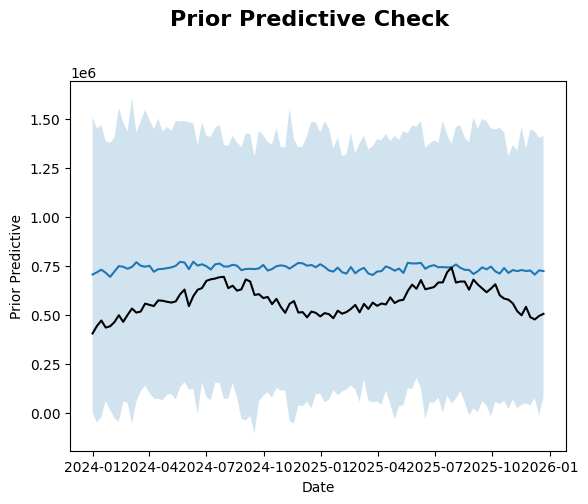

In [ ]:
mmm.sample_prior_predictive(
    X,
    y,
    samples=1_000,
    random_seed=SEED,
)

fig, axes = mmm.plot.diagnostics.prior_predictive()
fig.suptitle("Prior Predictive Check", fontsize=16, fontweight="bold", y=1.03)
plt.show()

In [ ]:
mmm.model_config

{'intercept': Prior("Normal", mu=0.6, sigma=0.1),
 'likelihood': Prior("Normal", sigma=Prior("HalfNormal", sigma=0.1), dims="date"),
 'gamma_control': Prior("Normal", mu=0, sigma=0.1, dims="control"),
 'gamma_fourier': Prior("Laplace", mu=0, b=0.2, dims="fourier_mode"),
 'adstock_alpha': Prior("Beta", alpha=1, beta=3, dims="channel"),
 'saturation_lam': Prior("Gamma", alpha=3, beta=1, dims="channel"),
 'saturation_beta': Prior("HalfNormal", sigma=2, dims="channel")}

In [ ]:
print("Observed mean:", y.mean())
print("Observed min:", y.min())
print("Observed max:", y.max())

Observed mean: 574892.9230769231
Observed min: 405782
Observed max: 742001


## 11. Fit the model

PyMC now uses MCMC sampling to learn a posterior distribution for the unknown parameters. Instead of producing one single coefficient, Bayesian modeling gives us a **distribution of plausible values**.

In [ ]:
mmm.fit(
    X=X,
    y=y,
    chains=4,
    tune=1_500,
    draws=1_000,
    target_accept=0.99,
    random_seed=SEED,
)

Output()

/usr/local/lib/python3.13/dist-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.
  warnings.warn(


Output()

<xarray.DataTree>
Group: /
│   Attributes: (12/24)
│       id:                         3be0ea23656dcb32
│       model_type:                 MMMM (Multi-Dimensional Marketing Mix Model)
│       version:                    0.0.2
│       sampler_config:             {}
│       model_config:               {"intercept": {"dist": "Normal", "kwargs": {"...
│       __serialization_version__:  1
│       ...                         ...
│       scaling:                    {"__type__": "pymc_marketing.mmm.scaling.Scal...
│       dag:                        null
│       treatment_nodes:            null
│       outcome_node:               null
│       mu_effects:                 []
│       cost_per_unit:              null
├── Group: /prior
│       Dimensions:                                         (chain: 1, draw: 1000,
│                                                            control: 5, date: 104,
│                                                            channel: 4, fourier_mode: 4)
│       Coordinates:
│         * chain                                           (chain) int64 8B 0
│         * draw                                            (draw) int64 8kB 0 1 ... 999
│         * control                                         (control) <U22 440B 'avg_...
│         * date                                            (date) datetime64[ns] 832B ...
│         * channel                                         (channel) <U18 288B 'ctv_...
│         * fourier_mode                                    (fourier_mode) <U5 80B 's...
│       Data variables: (12/18)
│           gamma_control                                   (chain, draw, control) float64 40kB ...
│           mu                                              (chain, draw, date) float64 832kB ...
│           y_original_scale                                (chain, draw, date) float64 832kB ...
│           yearly_seasonality_contribution                 (chain, draw, date) float64 832kB ...
│           channel_contribution_original_scale             (chain, draw, date, channel) float64 3MB ...
│           channel_contribution                            (chain, draw, date, channel) float64 3MB ...
│           ...                                              ...
│           intercept_contribution_original_scale           (chain, draw) float64 8kB ...
│           adstock_alpha                                   (chain, draw, channel) float64 32kB ...
│           yearly_seasonality_contribution_original_scale  (chain, draw, date) float64 832kB ...
│           control_contribution_original_scale             (chain, draw, date, control) float64 4MB ...
│           y_sigma                                         (chain, draw) float64 8kB ...
│           gamma_fourier                                   (chain, draw, fourier_mode) float64 32kB ...
│       Attributes:
│           created_at:                 2026-10-05T00:20:56.143958+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
│           pymc_marketing_version:     1.2.0
├── Group: /prior_predictive
│       Dimensions:  (chain: 1, draw: 1000, date: 104)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * date     (date) datetime64[ns] 832B 2024-01-01 2024-01-08 ... 2025-12-22
│       Data variables:
│           y        (chain, draw, date) float64 832kB 0.8695 1.754 ... 0.8507 1.153
│       Attributes:
│           created_at:                 2026-10-05T00:20:56.155289+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3

In [ ]:
# check divergences, should be close to 0
divergences = (
    mmm.idata["sample_stats"]["diverging"]
    .sum()
    .item()
)

print("Divergent transitions:", divergences)

Divergent transitions: 0


## 12. Generate posterior predictions

In [ ]:
mmm.sample_posterior_predictive(
    X=X,
    extend_idata=True,
    combined=True,
    random_seed=SEED,
)

Output()

<xarray.Dataset> Size: 7MB
Dimensions:           (date: 104, sample: 4000)
Coordinates:
  * date              (date) datetime64[ns] 832B 2024-01-01 ... 2025-12-22
  * sample            (sample) object 32kB MultiIndex
  * chain             (sample) int64 32kB 0 0 0 0 0 0 0 0 0 ... 3 3 3 3 3 3 3 3
  * draw              (sample) int64 32kB 0 1 2 3 4 5 ... 995 996 997 998 999
Data variables:
    y                 (date, sample) float64 3MB 0.5408 0.5267 ... 0.7026 0.6901
    y_original_scale  (date, sample) float64 3MB 4.013e+05 ... 5.12e+05
Attributes:
    created_at:                 2026-10-05T01:19:43.109667+00:00
    creation_library:           ArviZ
    creation_library_version:   1.3.1
    creation_library_language:  Python
    inference_library:          pymc
    inference_library_version:  6.3.2
    sample_dims:                ['sample']

A posterior predictive distribution asks: given everything the model learned, what sales values would it plausibly generate for each observed week?

## 13. Sampling diagnostics

In [ ]:
divergences = mmm.idata["sample_stats"]["diverging"].sum().item()
print("Divergent transitions:", divergences)

Divergent transitions: 0


Ideally we want zero divergent transitions. Divergences can indicate that the sampler had difficulty exploring the posterior correctly.

In [ ]:
posterior_variables = list(mmm.idata["posterior"].data_vars)

candidate_variables = [
    "adstock_alpha",
    "saturation_beta",
    "saturation_lam",
    "gamma_control",
    "gamma_fourier",
    "intercept_contribution",
    "y_sigma",
]

summary_variables = [v for v in candidate_variables if v in posterior_variables]

diagnostics = az.summary(
    mmm.idata,
    var_names=summary_variables,
)

diagnostics

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
adstock_alpha[ctv_spend],0.36,0.16,0.082,0.6,1892,1538,1.00,0.0036,0.0025
adstock_alpha[social_spend],0.257,0.19,0.021,0.6,3134,1882,1.00,0.003,0.0028
adstock_alpha[retail_media_spend],0.214,0.16,0.018,0.52,3464,2051,1.00,0.0024,0.0026
adstock_alpha[search_spend],0.188,0.161,0.012,0.51,2918,1979,1.00,0.0025,0.0028
saturation_beta[ctv_spend],0.116,0.073,0.042,0.25,1525,2088,1.00,0.0017,0.002
saturation_beta[social_spend],0.034,0.036,0.002,0.099,2800,1993,1.00,0.0007,0.0012
saturation_beta[retail_media_spend],0.064,0.051,0.0065,0.16,1864,1602,1.00,0.0011,0.0011
saturation_beta[search_spend],0.047,0.034,0.0047,0.11,2475,1930,1.00,0.00061,0.00058
saturation_lam[ctv_spend],2,1.22,0.6,4.2,2573,2454,1.00,0.022,0.025
saturation_lam[social_spend],3.49,2.34,0.62,7.8,2764,2365,1.00,0.042,0.038


### Two diagnostics to remember

- **R-hat** should be very close to `1.00`; it checks whether the chains converged toward the same distribution.
- **Effective sample size** (`ess_bulk`, `ess_tail`) tells us how much effective independent information we obtained from autocorrelated MCMC draws.

For this first model, focus on divergences, R-hat, and obvious model-fit problems.

## 14. Actual vs. predicted sales

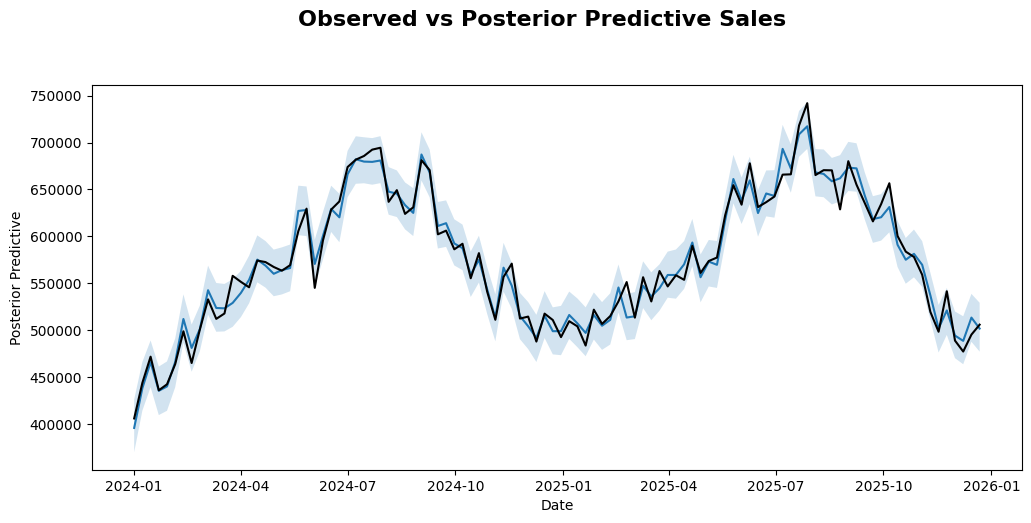

In [ ]:
fig, axes = mmm.plot.diagnostics.posterior_predictive(
    hdi_prob=0.94,
    figsize=(12, 5),
)
fig.suptitle("Observed vs Posterior Predictive Sales", fontsize=16, fontweight="bold", y=1.03)
plt.show()

A good historical fit is **necessary but not sufficient for causality**. A model can predict history well and still attribute the wrong amount of sales to marketing.

## 15. Residuals over time

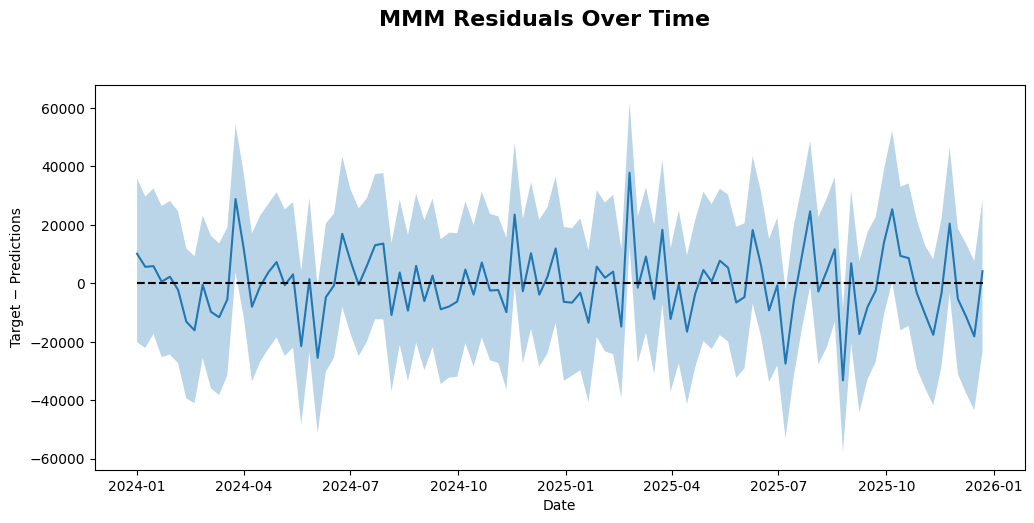

In [ ]:
fig, axes = mmm.plot.diagnostics.residuals_over_time(figsize=(12, 5))
fig.suptitle("MMM Residuals Over Time", fontsize=16, fontweight="bold", y=1.03)
plt.show()

A residual is approximately:

\[
Residual = Actual - Predicted
\]

If residuals contain a strong pattern, the model may be systematically missing something.

## 16. Estimated media contribution over time

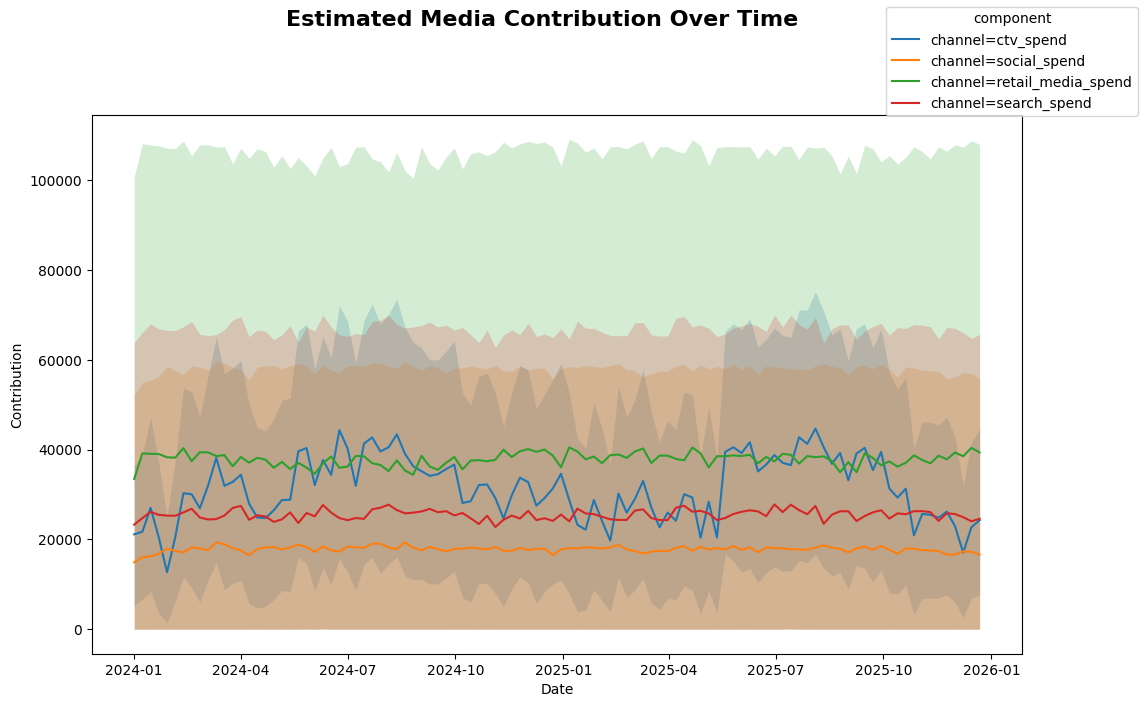

In [ ]:
fig, axes = mmm.plot.decomposition.contributions_over_time(
    include=["channels"],
    hdi_prob=0.94,
    figsize=(12, 7),
)
fig.suptitle("Estimated Media Contribution Over Time", fontsize=16, fontweight="bold", y=1.03)
plt.show()

Use careful wording: this is **estimated contribution under the observational MMM**, not proven causal lift. That distinction is the heart of Notebook 04.

## 17. Channel contribution share

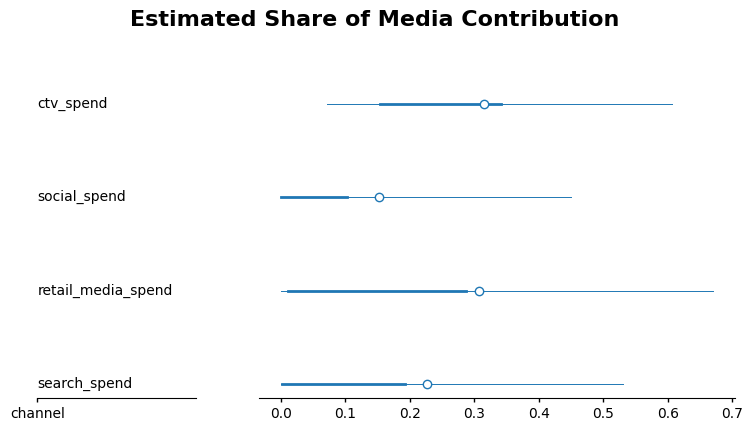

In [ ]:
fig, axes = mmm.plot.decomposition.channel_share_hdi(
    hdi_prob=0.94,
    figsize=(9, 4),
)
fig.suptitle("Estimated Share of Media Contribution", fontsize=16, fontweight="bold", y=1.08)
plt.show()

The uncertainty bars matter. If intervals overlap substantially, be cautious about claiming one channel is definitively better than another.

## 18. Overall sales decomposition

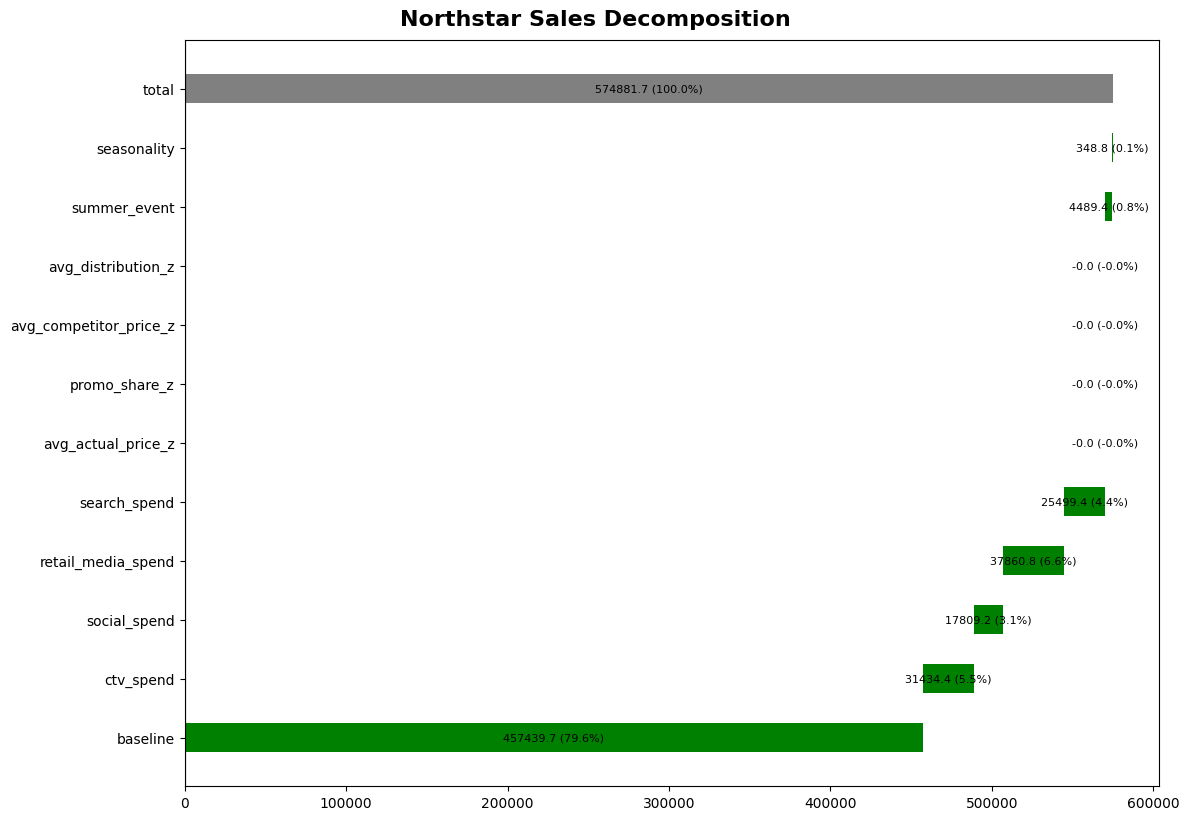

In [ ]:
fig, axes = mmm.plot.decomposition.waterfall(figsize=(12, 8))
plt.suptitle("Northstar Sales Decomposition", fontsize=16, fontweight="bold", y=1.02)
plt.show()

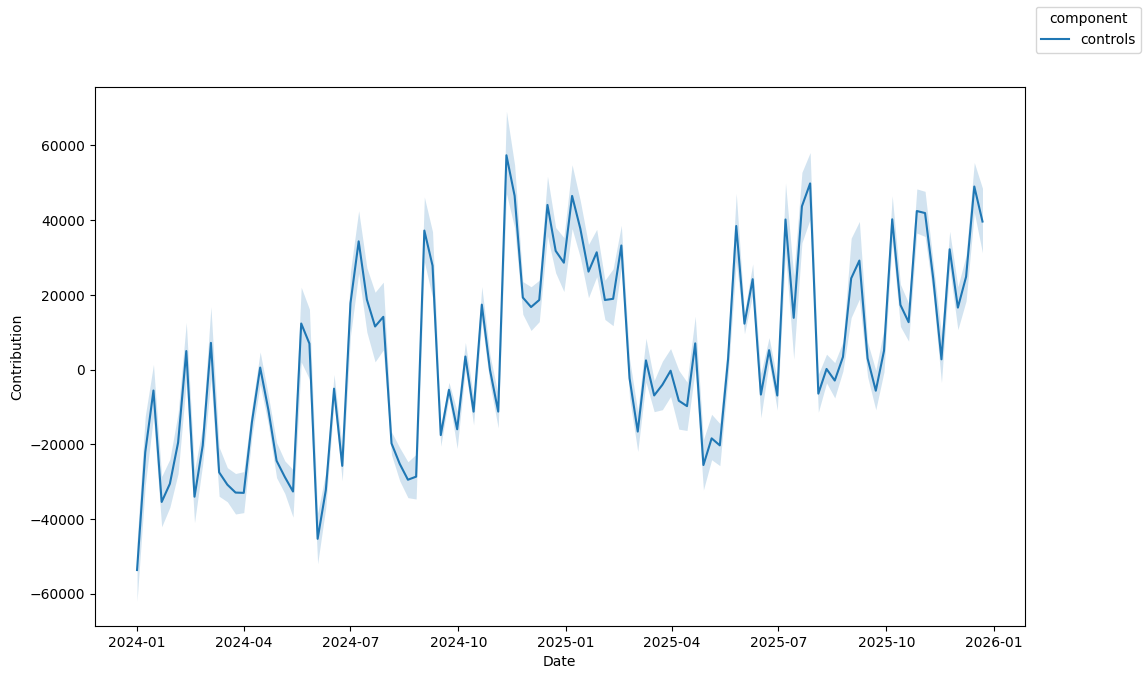

In [ ]:
fig, axes = mmm.plot.decomposition.contributions_over_time(
    include=["controls"],
    hdi_prob=0.94,
    figsize=(12, 7),
)

plt.show()

The decomposition connects the model back to the business story by separating baseline, media, controls, and seasonality.

## 19. Saturation / diminishing-return relationships

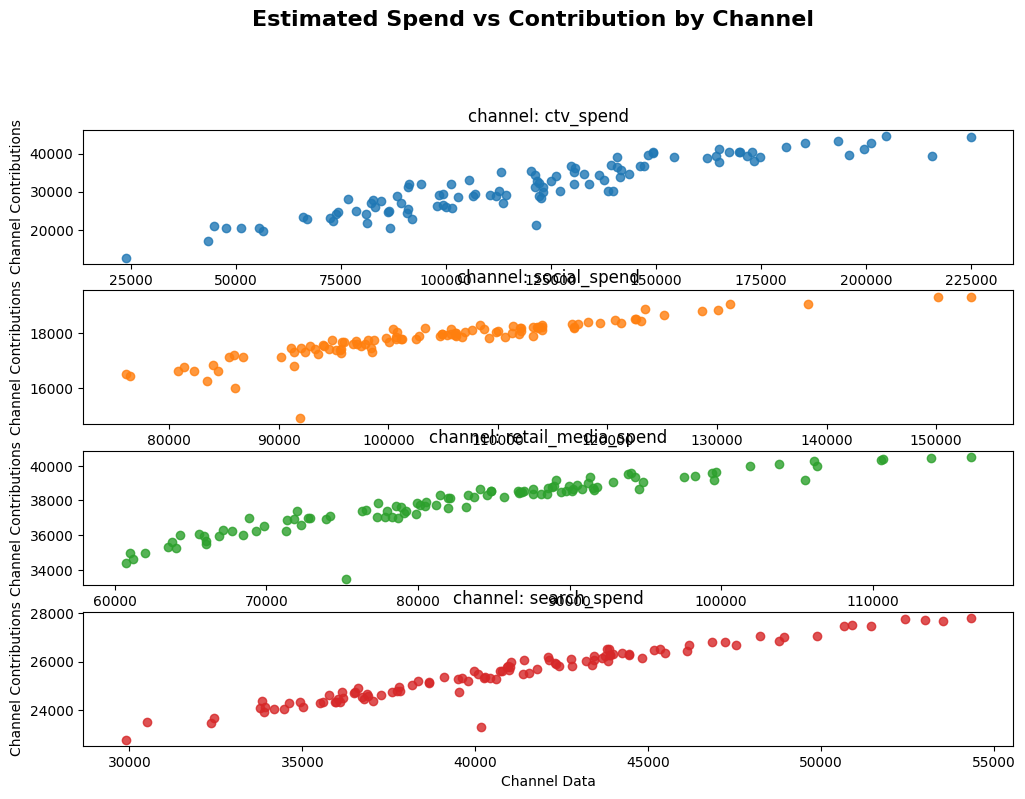

In [ ]:
fig, axes = mmm.plot.transformation.saturation_scatterplot(
    original_scale=True,
    figsize=(12, 8),
)
fig.suptitle("Estimated Spend vs Contribution by Channel", fontsize=16, fontweight="bold", y=1.03)
plt.show()

These plots ask how estimated contribution changes as channel spend changes. A relationship that flattens more quickly suggests stronger diminishing returns.

We should **not optimize budget yet**. First we need to challenge the observational model with experimental evidence.

## 20. Adstock parameters

In [ ]:
if "adstock_alpha" in mmm.idata["posterior"]:
    adstock_summary = az.summary(mmm.idata, var_names=["adstock_alpha"])
    display(adstock_summary)
else:
    print("adstock_alpha was not found under that exact variable name.")

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
adstock_alpha[ctv_spend],0.36,0.166,0.082,0.61,194,249,1.01,0.012,0.0044
adstock_alpha[social_spend],0.25,0.186,0.025,0.61,513,669,1.01,0.0078,0.0036
adstock_alpha[retail_media_spend],0.2,0.155,0.016,0.5,355,422,1.00,0.0077,0.0039
adstock_alpha[search_spend],0.17,0.144,0.0096,0.44,582,594,1.01,0.0052,0.0044


For geometric adstock, values closer to `0` imply short carryover and values closer to `1` imply longer carryover. Do not compare these against the hidden simulation truth yet—we first want the observational model's belief on its own.

## 21. Export article-ready summary tables

In [ ]:
channel_share = mmm.summary.channel_share_hdi()
waterfall_summary = mmm.summary.waterfall()
posterior_predictive_summary = mmm.summary.posterior_predictive()

display(channel_share)

,channel,mean,median,abs_error_94_lower,abs_error_94_upper
0,ctv_spend,0.173858,0.120778,0.007107,0.462799
1,social_spend,0.124807,0.050688,0.000019,0.481962
2,retail_media_spend,0.359142,0.277227,0.000110,0.885677
3,search_spend,0.342193,0.252961,0.000032,0.877499


In [ ]:
channel_share_path = OUTPUT_DIR / "baseline_mmm_channel_share.csv"
waterfall_path = OUTPUT_DIR / "baseline_mmm_waterfall.csv"
posterior_predictive_path = OUTPUT_DIR / "baseline_mmm_posterior_predictive.csv"
diagnostics_path = OUTPUT_DIR / "baseline_mmm_diagnostics.csv"
weekly_path = DATA_DIR / "northstar_national_weekly_mmm.csv"

channel_share.to_csv(channel_share_path, index=False)
waterfall_summary.to_csv(waterfall_path, index=False)
posterior_predictive_summary.to_csv(posterior_predictive_path, index=False)
diagnostics.to_csv(diagnostics_path)
weekly.to_csv(weekly_path, index=False)

print("Saved:")
print(channel_share_path)
print(waterfall_path)
print(posterior_predictive_path)
print(diagnostics_path)
print(weekly_path)

Saved:
/content/drive/MyDrive/northstar_cpg/outputs/baseline_mmm_channel_share.csv
/content/drive/MyDrive/northstar_cpg/outputs/baseline_mmm_waterfall.csv
/content/drive/MyDrive/northstar_cpg/outputs/baseline_mmm_posterior_predictive.csv
/content/drive/MyDrive/northstar_cpg/outputs/baseline_mmm_diagnostics.csv
/content/drive/MyDrive/northstar_cpg/data/northstar_national_weekly_mmm.csv


## 22. Save the fitted baseline model

In [ ]:
MODEL_PATH = MODEL_DIR / "northstar_baseline_mmm.nc"
mmm.save(MODEL_PATH)
print("Saved model:", MODEL_PATH)

Saved model: /content/drive/MyDrive/northstar_cpg/models/northstar_baseline_mmm.nc


Saving the fitted model lets Notebook 04 reuse it instead of fitting the baseline model again.

## 23. Questions to record before seeing an experiment

After running the model, write down the answers **before Notebook 04**:

1. Which channel does the MMM think contributes the most incremental units?
2. Which channel appears most saturated?
3. Which channel appears to have the longest carryover?
4. Which estimates have the widest uncertainty?
5. Does Paid Social look strong or weak?
6. Does the model fit observed sales reasonably well?
7. Are there obvious diagnostic concerns?

These become our **pre-experiment beliefs**.

# Notebook 03 conclusion

We have now built Northstar's first observational MMM using:

### Media
- Connected TV
- Paid Social
- Retail Media
- Paid Search

### Controls
- Northstar price
- promotion prevalence
- competitor price
- distribution
- event effects
- yearly seasonality

The model estimates adstock, saturation, contribution, and uncertainty.

But the unresolved question remains:

> **Are the modeled media contributions actually causal?**

Historical data alone cannot fully answer that.

## Next: Notebook 04 — Geo Incrementality Experiment

Notebook 04 will simulate a controlled media intervention across treatment markets, estimate causal lift, and compare that experimental result with the baseline MMM.

That comparison becomes the heart of our first technical article.